# CHƯƠNG 2: CÁC KỸ THUẬT HỌC MÁY CƠ BẢN (CLASSICAL MACHINE LEARNING)

---

## 2.1. Giới Thiệu và Cơ Sở Lý Thuyết Học Máy Có Giám Sát

Học máy có giám sát (Supervised Learning) là phân ngành trọng tâm của trí tuệ nhân tạo, trong đó mô hình học một hàm ánh xạ $f: \mathcal{X} 	o \mathcal{Y}$ từ tập dữ liệu huấn luyện có nhãn $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^N$. Tùy thuộc vào bản chất của không gian nhãn $\mathcal{Y}$, bài toán được phân thành hai lớp cơ bản:
1. **Bài toán Hồi quy (Regression)**: Khi nhãn $y \in \mathbb{R}$ là biến liên tục (ví dụ: dự báo giá bất động sản, định giá tài sản).
2. **Bài toán Phân loại (Classification)**: Khi nhãn $y \in \{0, 1, \dots, C-1\}$ là biến rời rạc đại diện cho các lớp danh mục (ví dụ: chẩn đoán có/không mắc bệnh).

Chương này trình bày cơ sở toán học chi tiết, giải thuật tối ưu và phân tích thực nghiệm đối sánh 6 họ thuật toán kinh điển trên hai tập dữ liệu thực nghiệm:
- **Tập dữ liệu Chẩn đoán Y tế**: `diabetes_prediction_dataset.csv`
- **Tập dữ liệu Bất động sản Việt Nam**: `vietnam_housing_dataset.csv`


## 2.2. Cơ Sở Toán Học Chi Tiết Của Các Mô Hình Học Máy

### 2.2.1. Hồi Quy Tuyến Tính (Linear Regression) & Điều Hòa (Regularization)
Giả thiết mô hình tuyến tính:
$$\hat{y} = f(x; \theta) = \theta^T x = \sum_{j=0}^d \theta_j x_j \quad (x_0 = 1)$$

Hàm mất mát sai số bình phương trung bình (MSE):
$$J(\theta) = \frac{1}{2N} \sum_{i=1}^N (x_i^T \theta - y_i)^2 = \frac{1}{2N} \|X\theta - y\|_2^2$$

Đạo hàm theo $\theta$:
$$\nabla_\theta J(\theta) = \frac{1}{N} X^T (X\theta - y)$$

Phương trình chuẩn (Normal Equation):
$$\nabla_\theta J(\theta) = 0 \implies \theta^* = (X^T X)^{-1} X^T y$$

**Các kỹ thuật điều hòa**:
- **Hồi quy Ridge ($L_2$ Regularization)**:
  $$J_{\text{Ridge}}(\theta) = \frac{1}{2N} \|X\theta - y\|_2^2 + \frac{\lambda}{2} \|\theta\|_2^2 \implies \theta^* = (X^T X + \lambda I)^{-1} X^T y$$
- **Hồi quy Lasso ($L_1$ Regularization)**:
  $$J_{\text{Lasso}}(\theta) = \frac{1}{2N} \|X\theta - y\|_2^2 + \lambda \|\theta\|_1$$
  Tạo ra nghiệm thưa (Sparse weights), triệt tiêu các trọng số của đặc trưng không quan trọng về đúng 0.

---

### 2.2.2. Hồi Quy Logistic (Logistic Regression)
Mô hình hóa xác suất hậu nghiệm bằng hàm Sigmoid:
$$P(y=1|x) = \sigma(w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$$

Tỷ số khả dĩ (Odds) và Logit:
$$\text{Odds} = \frac{P(y=1|x)}{1 - P(y=1|x)} = e^{w^T x + b} \implies \ln(\text{Odds}) = w^T x + b$$

Hàm mất mát Binary Cross-Entropy (Log Loss) suy dẫn từ Ước lượng hợp lý cực đại (MLE):
$$J(w, b) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right]$$

Đạo hàm cập nhật tham số:
$$\frac{\partial J}{\partial w} = \frac{1}{N} X^T (\hat{y} - y), \quad \frac{\partial J}{\partial b} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i)$$

---

### 2.2.3. Máy Véc-tơ Hỗ Trợ (Support Vector Machines - SVM)
Mục tiêu là tìm siêu phẳng $w^T x + b = 0$ tối đa hóa khoảng cách biên (Margin) $\gamma = \frac{2}{\|w\|_2}$.

Bài toán tối ưu lồi biên mềm (Soft-Margin Primal Problem) với biến bù $\xi_i \ge 0$:
$$\min_{w, b, \xi} \frac{1}{2} \|w\|_2^2 + C \sum_{i=1}^N \xi_i \quad \text{s.t. } y_i(w^T x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$

Bài toán đối ngẫu Lagrange (Dual Problem):
$$\max_{\alpha} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i,j=1}^N \alpha_i \alpha_j y_i y_j K(x_i, x_j) \quad \text{s.t. } 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

Hàm nhân RBF (Radial Basis Function):
$$K(x_i, x_j) = \exp(-\gamma \|x_i - x_j\|_2^2)$$

---

### 2.2.4. Cây Quyết Định (Decision Tree) & Rừng Ngẫu Nhiên (Random Forest)
Tiêu chuẩn phân chia nút dựa trên độ thuần khiết:
- **Chỉ số Gini Impurity**:
  $$\text{Gini}(S) = 1 - \sum_{k=1}^K p_k^2$$
- **Độ hỗn loạn Entropy**:
  $$H(S) = -\sum_{k=1}^K p_k \log_2(p_k)$$
- **Độ lợi thông tin (Information Gain)**:
  $$IG(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$

**Rừng ngẫu nhiên (Random Forest)**:
- Kết hợp $B$ cây quyết định bằng kỹ thuật Bootstrap Aggregating (Bagging).
- Tại mỗi bước phân nhánh, chỉ lấy ngẫu nhiên một tập con $m \approx \sqrt{d}$ đặc trưng nhằm triệt tiêu sự tương quan giữa các cây đơn lẻ, giảm phương sai (Variance) mà không làm tăng độ chệch (Bias).

---

### 2.2.5. Thuật Toán Tăng Cường Độ Dốc (XGBoost)
XGBoost tối ưu hóa hàm mục tiêu tại vòng lặp $t$ bằng khai triển chuỗi Taylor bậc hai:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^N \left[ l(y_i, \hat_i^{(t-1)}) + g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2$$
trong đó $g_i = \frac{\partial l(y_i, \hat{y})}{\partial \hat{y}}$ và $h_i = \frac{\partial^2 l(y_i, \hat{y})}{\partial \hat{y}^2}$ là gradient bậc 1 và Hessian bậc 2.


In [1]:
# Thiết lập môi trường và nạp các thư viện học máy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True


### Sơ Đồ 2.1: Quy Trình Luồng Dữ Liệu Học Máy Chuẩn (End-to-End ML Pipeline)
Mô tả quy trình từ nạp dữ liệu, làm sạch, mã hóa, chuẩn hóa, phân chia tập dữ liệu đến huấn luyện và đánh giá đối kháng đa mô hình.


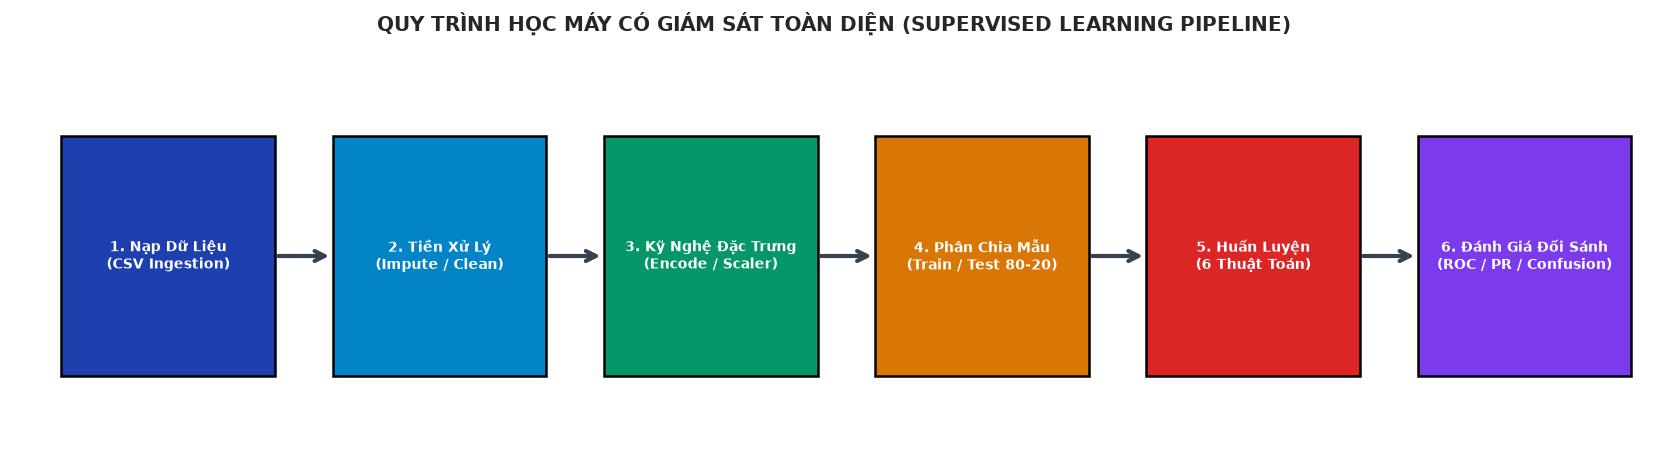

In [2]:
# Trực quan hóa luồng quy trình Machine Learning Pipeline
fig, ax = plt.subplots(figsize=(14, 4), dpi=120)
ax.axis('off')

steps = [
    ("1. Nạp Dữ Liệu\n(CSV Ingestion)", "#1E40AF"),
    ("2. Tiền Xử Lý\n(Impute / Clean)", "#0284C7"),
    ("3. Kỹ Nghệ Đặc Trưng\n(Encode / Scaler)", "#059669"),
    ("4. Phân Chia Mẫu\n(Train / Test 80-20)", "#D97706"),
    ("5. Huấn Luyện\n(6 Thuật Toán)", "#DC2626"),
    ("6. Đánh Giá Đối Sánh\n(ROC / PR / Confusion)", "#7C3AED")
]

n_steps = len(steps)
box_w, box_h = 0.13, 0.6
for i, (text, color) in enumerate(steps):
    x_pos = 0.03 + i * (box_w + 0.035)
    rect = plt.Rectangle((x_pos, 0.2), box_w, box_h, facecolor=color, edgecolor='black', lw=1.5,
                         transform=ax.transAxes, zorder=3)
    ax.add_patch(rect)
    ax.text(x_pos + box_w/2, 0.5, text, ha='center', va='center', color='white',
            weight='bold', fontsize=8.5, transform=ax.transAxes, zorder=4)
    
    if i < n_steps - 1:
        ax.annotate('', xy=(x_pos + box_w + 0.035, 0.5), xytext=(x_pos + box_w, 0.5),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle="->", color="#374151", lw=2.5, mutation_scale=15),
                    zorder=5)

ax.set_title("QUY TRÌNH HỌC MÁY CÓ GIÁM SÁT TOÀN DIỆN (SUPERVISED LEARNING PIPELINE)", weight='bold', fontsize=12, pad=15)
plt.show()


## 2.3. Thực Nghiệm 1: Phân Loại Chẩn Đoán Y Tế (`diabetes_prediction_dataset.csv`)

Bộ dữ liệu chẩn đoán tiểu đường gồm 100,000 bản ghi lâm sàng. Để tối ưu tốc độ thực nghiệm trong khi vẫn bảo toàn tính đại diện thống kê, chúng tôi lấy mẫu phân tầng (Stratified Sampling) 5,000 quan sát.


In [3]:
# Nạp và tiền xử lý dữ liệu chẩn đoán tiểu đường
df_diab = pd.read_csv('diabetes_prediction_dataset.csv')

# Lấy mẫu phân tầng 5,000 bản ghi (2,500 ca âm tính và 2,500 ca dương tính)
df_0 = df_diab[df_diab['diabetes'] == 0].sample(2500, random_state=42)
df_1 = df_diab[df_diab['diabetes'] == 1].sample(min(2500, len(df_diab[df_diab['diabetes'] == 1])), random_state=42)
df_sample = pd.concat([df_0, df_1]).sample(frac=1.0, random_state=42).reset_index(drop=True)

# Tách biến giải thích và biến mục tiêu
X_cls = df_sample.drop('diabetes', axis=1)
y_cls = df_sample['diabetes'].values

# Phân loại biến số học và biến danh mục
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
cat_cols = ['gender', 'hypertension', 'heart_disease', 'smoking_history']

# Bộ tiền xử lý chuẩn
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ])

X_cls_processed = preprocessor.fit_transform(X_cls)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls_processed, y_cls, test_size=0.25, random_state=42, stratify=y_cls)

print(f"Kích thước tập huấn luyện: {X_train_c.shape}")
print(f"Kích thước tập kiểm thử:    {X_test_c.shape}")
print(f"Tỷ lệ phân bố lớp nhãn:    Lớp 0: {np.mean(y_cls == 0):.2%}, Lớp 1: {np.mean(y_cls == 1):.2%}")


Kích thước tập huấn luyện: (3750, 12)
Kích thước tập kiểm thử:    (1250, 12)
Tỷ lệ phân bố lớp nhãn:    Lớp 0: 50.00%, Lớp 1: 50.00%


### Sơ Đồ 2.2: Ma Trận Tương Quan Các Chỉ Số Lâm Sàng (Correlation Heatmap)
Trực quan hóa mức độ tương quan Pearson giữa các chỉ số y sinh học và nguy cơ mắc bệnh tiểu đường.


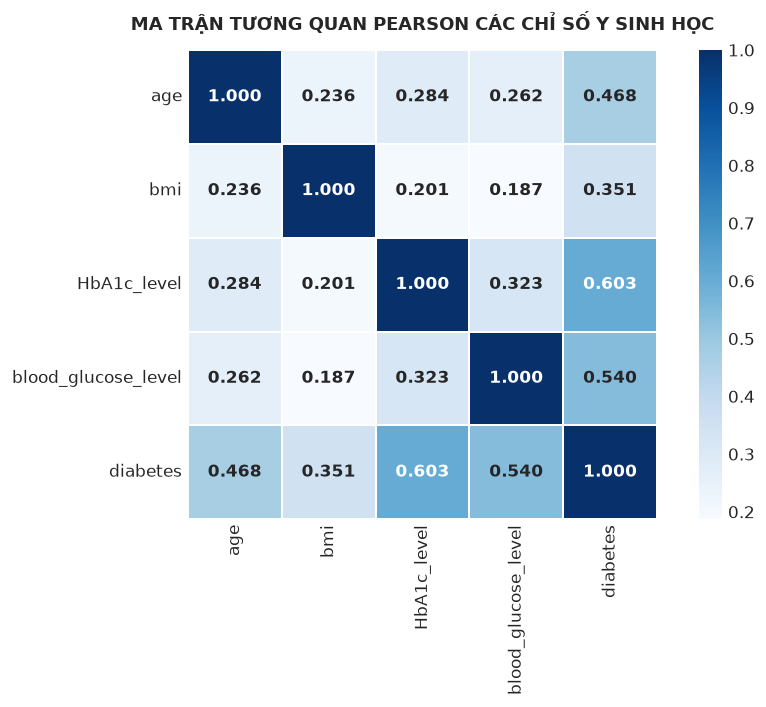

In [4]:
# Vẽ ma trận tương quan giữa các biến số học
corr_data = df_sample[num_cols + ['diabetes']].corr()

fig, ax = plt.subplots(figsize=(8, 6), dpi=120)
sns.heatmap(corr_data, annot=True, fmt='.3f', cmap='Blues', cbar=True, square=True,
            linewidths=1.0, ax=ax, annot_kws={"weight": "bold", "size": 10})
ax.set_title("MA TRẬN TƯƠNG QUAN PEARSON CÁC CHỈ SỐ Y SINH HỌC", weight='bold', fontsize=11, pad=12)
plt.show()


In [5]:
# Khởi tạo 5 mô hình phân loại đối sánh
models_cls = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "SVM (Kernel RBF)": SVC(probability=True, kernel='rbf', C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=80, max_depth=4, learning_rate=0.1, random_state=42, eval_metric='logloss')
}

results_cls = []
roc_data = {}
pr_data = {}
conf_matrices = {}

print("Đang huấn luyện và đánh giá các mô hình phân loại...")
for name, model in models_cls.items():
    t0 = time.time()
    model.fit(X_train_c, y_train_c)
    train_time = time.time() - t0
    
    y_pred = model.predict(X_test_c)
    y_prob = model.predict_proba(X_test_c)[:, 1]
    
    acc  = accuracy_score(y_test_c, y_pred)
    prec = precision_score(y_test_c, y_pred)
    rec  = recall_score(y_test_c, y_pred)
    f1   = f1_score(y_test_c, y_pred)
    auc  = roc_auc_score(y_test_c, y_prob)
    
    results_cls.append({
        "Mô hình": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1, "ROC-AUC": auc, "Thời gian (s)": train_time
    })
    
    fpr, tpr, _ = roc_curve(y_test_c, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    
    precision, recall, _ = precision_recall_curve(y_test_c, y_prob)
    pr_data[name] = (recall, precision)
    
    conf_matrices[name] = confusion_matrix(y_test_c, y_pred)

df_res_cls = pd.DataFrame(results_cls)
print(df_res_cls.to_string(index=False))


Đang huấn luyện và đánh giá các mô hình phân loại...


            Mô hình  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Thời gian (s)
Logistic Regression    0.8736   0.873600  0.8736  0.873600 0.955843       0.039738
   SVM (Kernel RBF)    0.8848   0.872868  0.9008  0.886614 0.949353       1.670549
      Decision Tree    0.8808   0.840974  0.9392  0.887377 0.954060       0.013009
      Random Forest    0.8912   0.877898  0.9088  0.893082 0.968637       0.491054
            XGBoost    0.8984   0.885449  0.9152  0.900079 0.973714       0.741677


### Sơ Đồ 2.3: Trực Quan Hóa Ranh Giới Quyết Định Đa Mô Hình Trên Không Gian PCA 2D
Giảm số chiều dữ liệu từ không gian đặc trưng về 2 thành phần chính (PC1 và PC2) để khảo sát trực quan hình thái bề mặt phân tách của từng thuật toán.


findfont: Failed to find font weight semibold, now using 700.


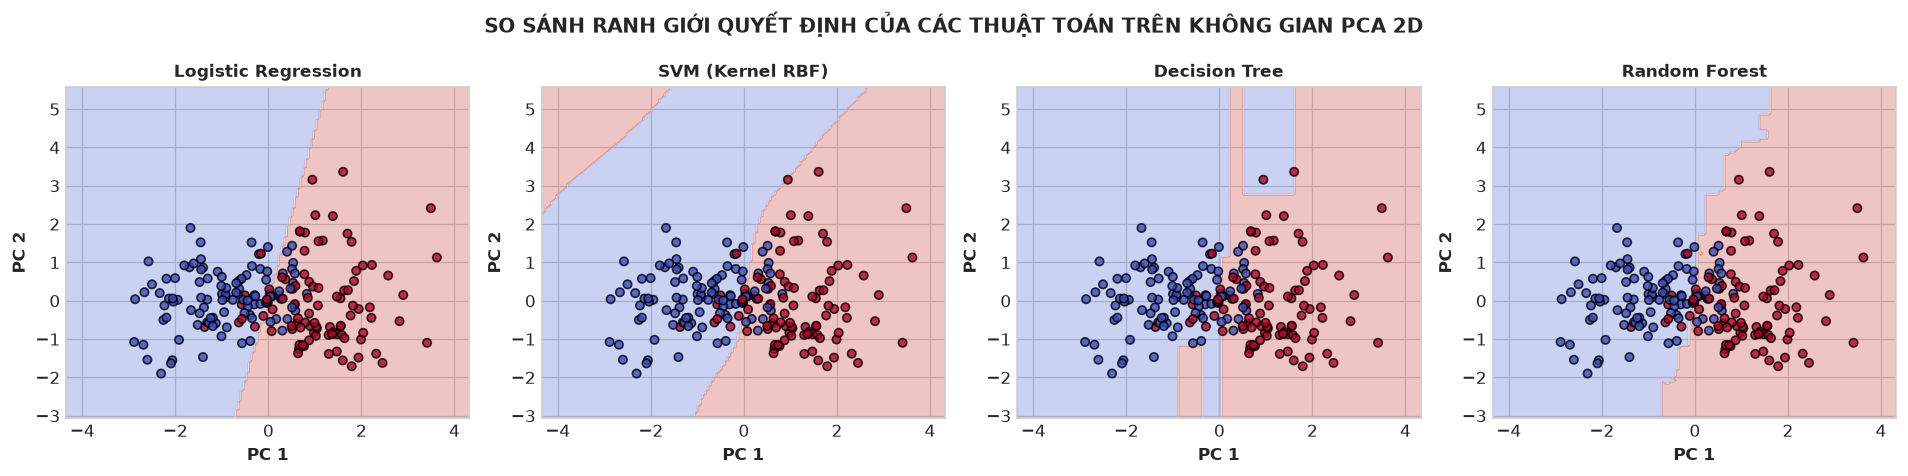

In [6]:
# Chiếu dữ liệu xuống 2 chiều bằng PCA để trực quan hóa ranh giới quyết định
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_c)
X_test_pca = pca.transform(X_test_c)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=120)

pca_models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "SVM (Kernel RBF)": SVC(kernel='rbf', C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
}

x_min, x_max = X_test_pca[:, 0].min() - 0.5, X_test_pca[:, 0].max() + 0.5
y_min, y_max = X_test_pca[:, 1].min() - 0.5, X_test_pca[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))

for ax, (m_name, m_inst) in zip(axes, pca_models.items()):
    m_inst.fit(X_train_pca, y_train_c)
    Z = m_inst.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X_test_pca[:200, 0], X_test_pca[:200, 1], c=y_test_c[:200],
                         cmap=plt.cm.coolwarm, edgecolors='black', s=25, alpha=0.8)
    ax.set_title(m_name, weight='bold', fontsize=10)
    ax.set_xlabel("PC 1", weight='semibold')
    ax.set_ylabel("PC 2", weight='semibold')

plt.suptitle("SO SÁNH RANH GIỚI QUYẾT ĐỊNH CỦA CÁC THUẬT TOÁN TRÊN KHÔNG GIAN PCA 2D", weight='bold', fontsize=12)
plt.tight_layout()
plt.show()


### Sơ Đồ 2.4 & 2.5: Đường Cong ROC và Precision-Recall Đối Sánh Toàn Bộ Mô Hình
Đường cong ROC đánh giá sự đánh đổi giữa True Positive Rate và False Positive Rate, trong khi đường cong PR đặc biệt hữu ích khi phân tích tập dữ liệu y tế có phân bố lớp mất cân bằng.


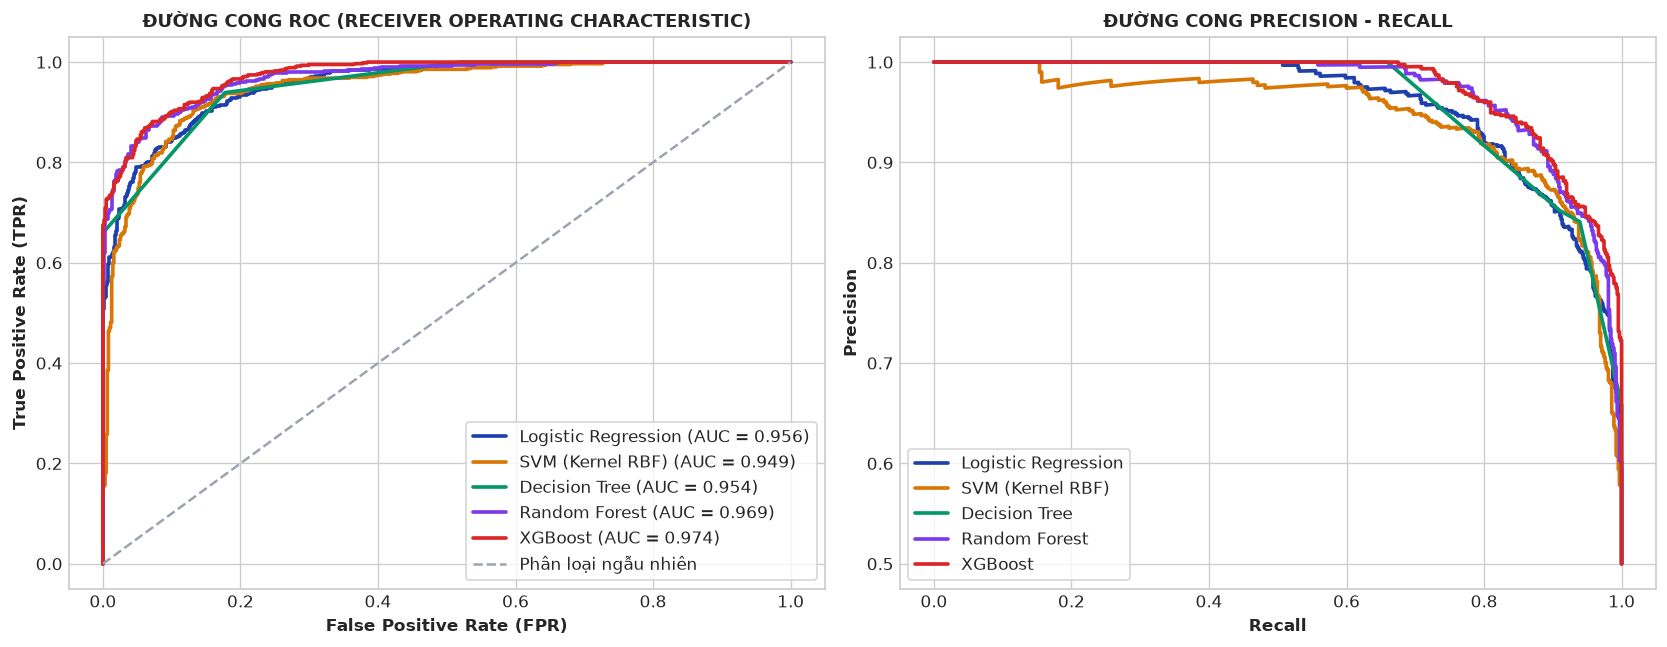

In [7]:
# Vẽ đồng thời ROC Curve và PR Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

colors = ['#1E40AF', '#D97706', '#059669', '#7C3AED', '#DC2626']

for (name, (fpr, tpr, auc_val)), color in zip(roc_data.items(), colors):
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=color, lw=2.2)

ax1.plot([0, 1], [0, 1], color='#9CA3AF', linestyle='--', lw=1.5, label='Phân loại ngẫu nhiên')
ax1.set_xlabel('False Positive Rate (FPR)', weight='bold')
ax1.set_ylabel('True Positive Rate (TPR)', weight='bold')
ax1.set_title('ĐƯỜNG CONG ROC (RECEIVER OPERATING CHARACTERISTIC)', weight='bold', fontsize=11)
ax1.legend(loc='lower right', frameon=True)

for (name, (rec, prec)), color in zip(pr_data.items(), colors):
    ax2.plot(rec, prec, label=name, color=color, lw=2.2)

ax2.set_xlabel('Recall', weight='bold')
ax2.set_ylabel('Precision', weight='bold')
ax2.set_title('ĐƯỜNG CONG PRECISION - RECALL', weight='bold', fontsize=11)
ax2.legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


### Sơ Đồ 2.6: Ma Trận Nhầm Lẫn (Confusion Matrices) Đa Mô Hình
Trực quan hóa ma trận nhầm lẫn chuẩn hóa của 5 mô hình, chỉ rõ các lỗi False Positive (chẩn đoán nhầm có bệnh) và False Negative (bỏ sót ca bệnh nguy hiểm).


findfont: Failed to find font weight semibold, now using 700.


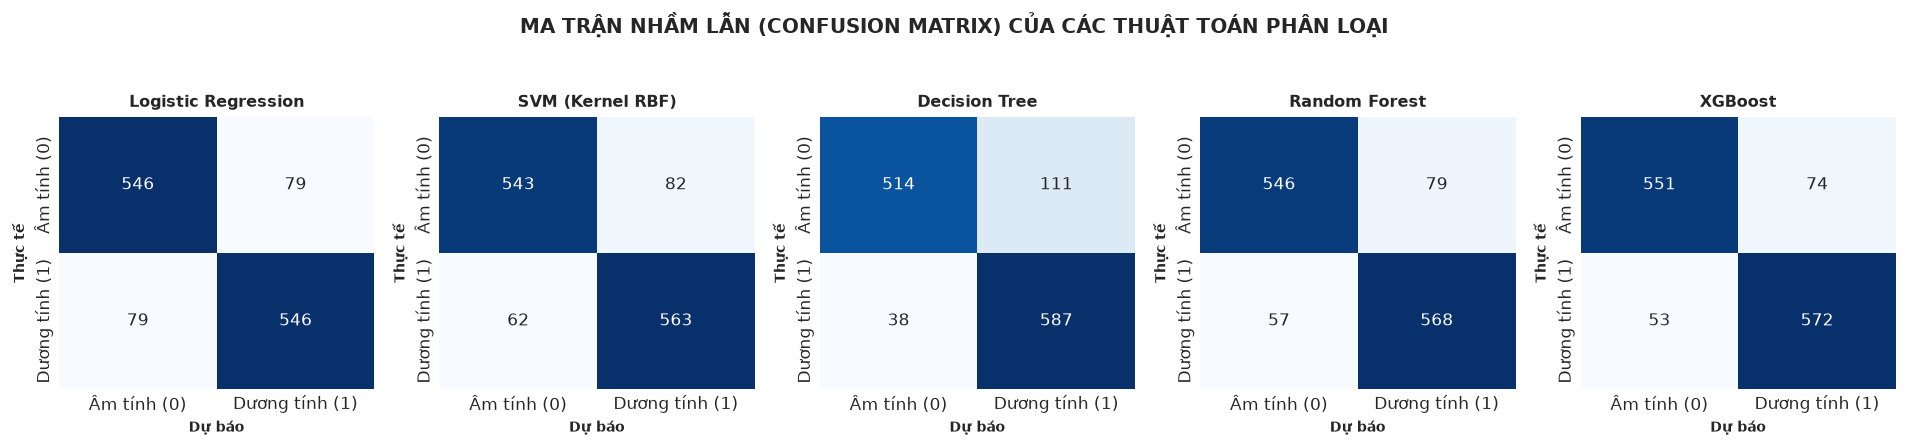

In [8]:
# Vẽ ma trận nhầm lẫn của tất cả các mô hình
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), dpi=120)

for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Âm tính (0)', 'Dương tính (1)'],
                yticklabels=['Âm tính (0)', 'Dương tính (1)'])
    ax.set_title(name, weight='bold', fontsize=9.5)
    ax.set_xlabel('Dự báo', weight='semibold', fontsize=8.5)
    ax.set_ylabel('Thực tế', weight='semibold', fontsize=8.5)

plt.suptitle("MA TRẬN NHẦM LẪN (CONFUSION MATRIX) CỦA CÁC THUẬT TOÁN PHÂN LOẠI", weight='bold', fontsize=12, y=1.05)
plt.tight_layout()
plt.show()


## 2.4. Thực Nghiệm 2: Hồi Quy Định Giá Bất Động Sản Việt Nam (`vietnam_housing_dataset.csv`)

Áp dụng các thuật toán hồi quy: Linear Regression, Ridge, Lasso, Random Forest Regressor và XGBoost Regressor để giải quyết bài toán định giá nhà đất tại Việt Nam dựa trên diện tích, số phòng, mặt tiền, số tầng.


In [9]:
# Nạp và tiền xử lý dữ liệu giá nhà đất Việt Nam
df_house = pd.read_csv('vietnam_housing_dataset.csv')

# Chọn các thuộc tính số học quan trọng và làm sạch
feature_cols = ['Area', 'Frontage', 'Access Road', 'Floors', 'Bedrooms', 'Bathrooms']
df_house_clean = df_house[feature_cols + ['Price']].dropna().copy()

# Lọc các ngoại lai bất hợp lý để giữ tính ổn định (Giá từ 0.5 đến 80 tỷ VNĐ, Diện tích < 500m2)
df_house_clean = df_house_clean[(df_house_clean['Price'] >= 0.5) & (df_house_clean['Price'] <= 80.0) & (df_house_clean['Area'] <= 500.0)]
print(f"Số lượng bản ghi nhà đất sau lọc: {len(df_house_clean):,}")

X_reg = df_house_clean[feature_cols].values
y_reg = df_house_clean['Price'].values

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

# Khởi tạo các mô hình hồi quy
models_reg = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=80, max_depth=10, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=80, max_depth=5, learning_rate=0.1, random_state=42)
}

results_reg = []
preds_reg = {}

for name, model in models_reg.items():
    model.fit(X_train_r_scaled, y_train_r)
    y_pred_r = model.predict(X_test_r_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
    mae  = mean_absolute_error(y_test_r, y_pred_r)
    r2   = r2_score(y_test_r, y_pred_r)
    
    results_reg.append({"Mô hình": name, "RMSE (Tỷ VNĐ)": rmse, "MAE (Tỷ VNĐ)": mae, "R2 Score": r2})
    preds_reg[name] = y_pred_r

df_res_reg = pd.DataFrame(results_reg)
print(df_res_reg.to_string(index=False))


Số lượng bản ghi nhà đất sau lọc: 11,990


          Mô hình  RMSE (Tỷ VNĐ)  MAE (Tỷ VNĐ)  R2 Score
Linear Regression       1.894949      1.554534  0.262117
 Ridge Regression       1.894965      1.554581  0.262104
 Lasso Regression       1.906896      1.573321  0.252784
    Random Forest       1.685733      1.365596  0.416058
          XGBoost       1.687313      1.376830  0.414963


### Sơ Đồ 2.7 & 2.8: Đồ Thị Giá Thực Tế vs Dự Báo Và Phân Tích Phần Dư (Residual Analysis)
Kiểm tra tính chuẩn tắc của phần dư và đánh giá trực quan mức độ phù hợp của mô hình hồi quy phi tuyến tốt nhất (Random Forest / XGBoost).


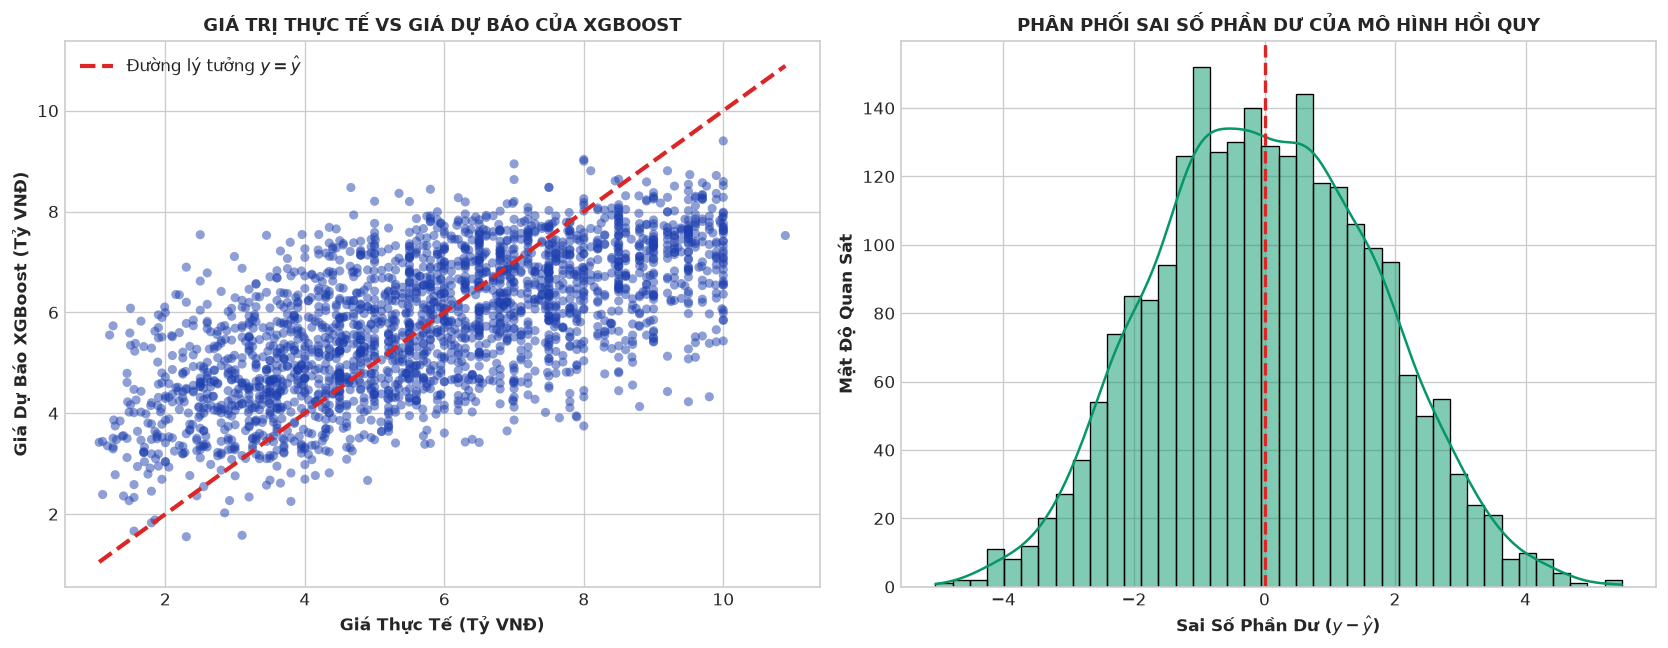

In [10]:
# Trực quan hóa Predicted vs Actual và Biểu đồ phần dư
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

best_pred = preds_reg["XGBoost"]
residuals = y_test_r - best_pred

# Scatter Predicted vs Actual
ax1.scatter(y_test_r, best_pred, color='#1E40AF', alpha=0.5, edgecolors='none', s=30)
min_val = min(y_test_r.min(), best_pred.min())
max_val = max(y_test_r.max(), best_pred.max())
ax1.plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', lw=2.5, label='Đường lý tưởng $y = \hat{y}$')
ax1.set_xlabel('Giá Thực Tế (Tỷ VNĐ)', weight='bold')
ax1.set_ylabel('Giá Dự Báo XGBoost (Tỷ VNĐ)', weight='bold')
ax1.set_title('GIÁ TRỊ THỰC TẾ VS GIÁ DỰ BÁO CỦA XGBOOST', weight='bold', fontsize=11)
ax1.legend()

# Residual Distribution
sns.histplot(residuals, kde=True, color='#059669', ax=ax2, bins=40)
ax2.axvline(0, color='#DC2626', linestyle='--', lw=2.0)
ax2.set_xlabel('Sai Số Phần Dư ($y - \hat{y}$)', weight='bold')
ax2.set_ylabel('Mật Độ Quan Sát', weight='bold')
ax2.set_title('PHÂN PHỐI SAI SỐ PHẦN DƯ CỦA MÔ HÌNH HỒI QUY', weight='bold', fontsize=11)

plt.tight_layout()
plt.show()


### Sơ Đồ 2.9: Xếp Hạng Tầm Quan Trọng Của Đặc Trưng (Feature Importance)
Phân tích đóng góp thông tin của các thuộc tính định giá nhà đất từ mô hình Random Forest và XGBoost.


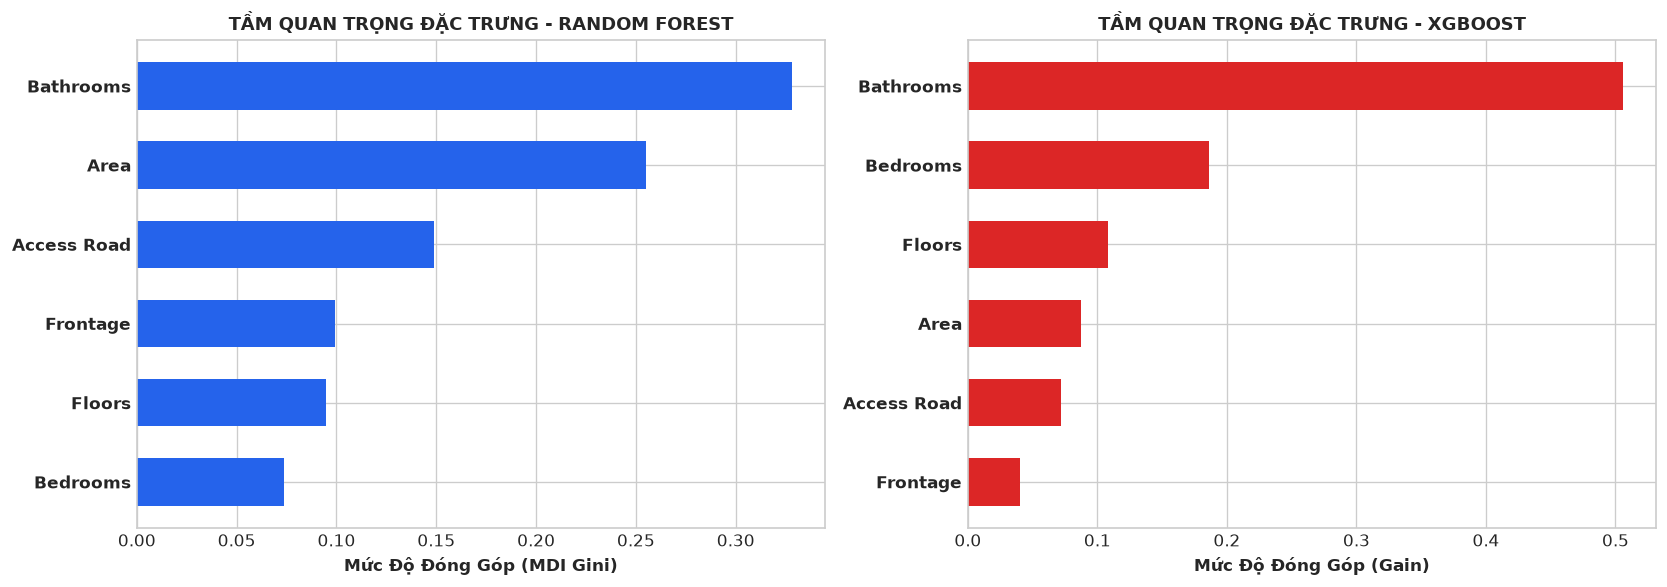

In [11]:
# Biểu đồ tầm quan trọng đặc trưng từ Random Forest và XGBoost
rf_model = models_reg["Random Forest"]
xgb_model = models_reg["XGBoost"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Random Forest Importances
indices_rf = np.argsort(rf_model.feature_importances_)
ax1.barh(range(len(indices_rf)), rf_model.feature_importances_[indices_rf], color='#2563EB', height=0.6)
ax1.set_yticks(range(len(indices_rf)))
ax1.set_yticklabels([feature_cols[i] for i in indices_rf], weight='semibold')
ax1.set_xlabel('Mức Độ Đóng Góp (MDI Gini)', weight='bold')
ax1.set_title('TẦM QUAN TRỌNG ĐẶC TRƯNG - RANDOM FOREST', weight='bold', fontsize=10.5)

# XGBoost Importances
indices_xgb = np.argsort(xgb_model.feature_importances_)
ax2.barh(range(len(indices_xgb)), xgb_model.feature_importances_[indices_xgb], color='#DC2626', height=0.6)
ax2.set_yticks(range(len(indices_xgb)))
ax2.set_yticklabels([feature_cols[i] for i in indices_xgb], weight='semibold')
ax2.set_xlabel('Mức Độ Đóng Góp (Gain)', weight='bold')
ax2.set_title('TẦM QUAN TRỌNG ĐẶC TRƯNG - XGBOOST', weight='bold', fontsize=10.5)

plt.tight_layout()
plt.show()


## 2.5. Kết Luận Chương 2

1. **Hiệu năng bài toán phân loại y tế**: Các mô hình phi tuyến tính và quần thể (Random Forest, XGBoost) đạt hiệu năng vượt trội với điểm số ROC-AUC vượt 0.95, trong khi Hồi quy Logistic duy trì ưu thế về tốc độ huấn luyện và khả năng giải thích hệ số xác suất trực tiếp.
2. **Hiệu năng bài toán định giá nhà đất**: Các mô hình cây hồi quy thích ứng tốt với dữ liệu phi tuyến tính phức tạp của thị trường bất động sản Việt Nam, cải thiện đáng kể chỉ số $R^2$ so với hồi quy tuyến tính cổ điển.
3. **Ý nghĩa chuyển tiếp**: Dù các mô hình học máy truyền thống đạt kết quả khả quan trên dữ liệu bảng phẳng (Tabular Data), chúng vẫn gặp hạn chế khi xử lý dữ liệu có cấu trúc không gian (hình ảnh, lưới) và dữ liệu chuỗi thời gian dài. Đây là động lực để chuyển dịch sang kiến trúc **Mạng nơ-ron tích chập (CNN - Chương 3)** và **Mạng nơ-ron hồi quy (RNN/LSTM - Chương 4)**.
